# Лабораторная работа 6. Нейронная сеть

|  |  |
|---|---|
| Дисциплина | Машинное обучение |
| Студент | Масенькин Максим |
| Группа | ПИбд-41 |
| Вариант | 20 |

## Задание

Использовать нейронную сеть (чётные варианты — `MLPRegressor`, нечётные — `MLPClassifier`) для
своих данных, самостоятельно сформулировав задачу. Интерпретировать результаты и оценить, насколько
хорошо она подходит для решения сформулированной задачи.

| Пункт задания | Вариант 20 |
|---|---|
| Тип сети | `MLPRegressor` (20 — чётный вариант) |
| Данные | сделки инсайдеров Tesla, 156 записей |
| Задача | предсказать сумму сделки по типу сделки, должности инсайдера, числу акций и дате |
| Модель | `MLPRegressor` в конвейере с `OneHotEncoder` и `StandardScaler`, число нейронов и `alpha` подобраны `GridSearchCV` |
| Пособие | «Теория и практика машинного обучения»: достоинства и недостатки нейронных сетей — стр. 111–112; многослойный персептрон и функция активации — стр. 119–122; `MLPClassifier` и стандартизация признаков — стр. 218–222, листинг 58; обратное распространение ошибки — стр. 223–228; пункт «Регуляризация и сеть прямого распространения» — стр. 228–236, листинги 61–64 |

## Ход работы

1. Загрузить данные о сделках и подготовить признаки.
2. Собрать конвейер с нейронной сетью.
3. Подобрать число нейронов и коэффициент регуляризации.
4. Сравнить сеть с линейной регрессией.
5. Оценить, насколько сеть подходит для задачи.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    cross_val_predict,
    cross_val_score,
    train_test_split,
)
from sklearn.neural_network import MLPRegressor

from mllab import RANDOM_STATE
from mllab.datasets import load_tesla
from mllab.metrics import regression_report
from mllab.preprocessing import build_pipeline, calendar_features
from mllab.reporting import make_table


CATEGORICAL = ["transaction", "relationship"]
NUMERIC = ["log_shares", "month", "year"]
TEST_SIZE = 0.25
FOLDS = 10
SEARCH_FOLDS = 5
MAX_ITER = 5000
LAYERS = [(5,), (20,), (50,), (20, 20), (50, 50)]
ALPHAS = [0.01, 0.1, 1, 3, 10, 30, 100]
NETWORK_COLOR = "#eb6834"
GROUPS = {
    "продажа": ("#2a78d6", "o"),
    "платное исполнение опциона": ("#eb6834", "s"),
    "нулевая сделка": ("#1baf7a", "D"),
}

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 120)

## 1. Данные и признаки

Набор содержит 156 сделок семи инсайдеров Tesla с ноября 2021 по декабрь 2022, продажи акций и
исполнения опционов, т. е. покупки акций по заранее оговорённой цене.

Задача работы — предсказать сумму сделки по её типу, должности инсайдера, числу акций и дате.
Сумма — число, поэтому это задача регрессии. Признаки и разбиение на обучающую и отложенную выборки
те же, что в ЛР 5, так нейронную сеть можно сравнить с линейной регрессией и проверить, что даёт
нелинейность.

При загрузке набор приведён к удобному виду:

- имена столбцов переведены в snake_case;
- числа с разделителями тысяч вида `"2,056,775"` преобразованы в целые;
- даты разобраны из строк.

In [2]:
tesla = load_tesla()
value = tesla["value"]
zero = value == 0
X_tesla = pd.concat(
    [
        tesla[CATEGORICAL],
        np.log1p(tesla["shares"]).rename("log_shares"),
        calendar_features(tesla["date"], ("month", "year")),
    ],
    axis=1,
)
group = pd.Series(
    np.select(
        [zero, tesla["transaction"] == "Sale"],
        ["нулевая сделка", "продажа"],
        "платное исполнение опциона",
    ),
    index=tesla.index,
)
sales = int((group == "продажа").sum())
X_train, X_test, value_train, value_test = train_test_split(
    X_tesla, value, test_size=TEST_SIZE, stratify=X_tesla["transaction"], random_state=RANDOM_STATE
)

make_table(
    {
        "сделок": len(tesla),
        "период": f"{tesla['date'].min():%d.%m.%Y} – {tesla['date'].max():%d.%m.%Y}",
        "продаж / исполнений опционов": f"{sales} / {len(tesla) - sales}",
        "из них с нулевой суммой": int(zero.sum()),
        "акций в сделке": f"{tesla['shares'].min():,} – {tesla['shares'].max():,}",
        "медианная сумма, $": f"{value.median():,.0f}",
        "максимальная сумма, $": f"{value.max():,.0f}",
    }
)

,значение
,
сделок,156
период,10.11.2021 – 28.12.2022
продаж / исполнений опционов,99 / 57
из них с нулевой суммой,18
акций в сделке,"121 – 11,920,000"
"медианная сумма, $","2,026,823"
"максимальная сумма, $","2,278,695,421"


Суммы лежат от нуля до 2.28 млрд \$, медиана — 2.03 млн \$, число акций — от 121 до 11.92 млн.

Признаки модели:

- `transaction` — тип сделки: `Sale` или `Option Exercise`;
- `relationship` — должность инсайдера: генеральный директор Илон Маск (CEO), финансовый директор
  (CFO), главный бухгалтер (CAO), вице-президент по силовым установкам и энергетике (SVP) или член
  совета директоров (Director);
- `log_shares` — логарифм числа акций $\ln(1 + \text{акций})$;
- `month`, `year` — месяц и год сделки.

In [3]:
X_tesla.head()

,transaction,relationship,log_shares,month,year
0,Sale,Chief Financial Officer,9.254931,3,2022
1,Sale,Chief Accounting Officer,7.810758,3,2022
2,Sale,SVP Powertrain and Energy Eng.,7.169350,3,2022
3,Option Exercise,Chief Accounting Officer,8.873328,3,2022
4,Option Exercise,SVP Powertrain and Energy Eng.,7.858254,3,2022


Модель предсказывает логарифм суммы $y = \ln(1 + \text{сумма})$, т. к. суммы различаются на
несколько порядков. Цена акции в признаки не входит: вместе с числом акций она даёт сумму без
всякой модели.

Сделки делятся на три группы, которые линейная регрессия описывает по-разному: 99 продаж, 39
платных исполнений опционов и 18 нулевых сделок, т. е. исполнений опционов с нулевой суммой.

## 2. Многослойный персептрон

Линейная регрессия складывает вклады признаков с весами. Многослойный персептрон (MLP) ставит между
признаками и прогнозом скрытый слой нейронов. Каждый нейрон считает свою взвешенную сумму признаков
и пропускает её через функцию активации:

$$h_k = \max\Bigl(0,\ b_k + \sum_{j=1}^{m} v_{kj} x_j\Bigr), \qquad k = 1, \dots, K ,$$

где $K$ — число нейронов в слое, $v_{kj}$ — веса $k$-го нейрона, $b_k$ — его сдвиг. Прогноз —
взвешенная сумма выходов нейронов:

$$\hat{y} = w_0 + \sum_{k=1}^{K} w_k h_k .$$

Скрытых слоёв может быть несколько, тогда каждый следующий слой получает на вход выходы
предыдущего. У выходного нейрона в регрессии функции активации нет, иначе прогноз не мог бы быть
любым числом.

Функция $\max(0, z)$ называется ReLU: отрицательную сумму она заменяет нулём, а положительную
пропускает как есть. Без функции активации сеть сводится к линейной регрессии: если $h = 2x$ и
$\hat{y} = 3h$, то $\hat{y} = 6x$, и сколько слоёв ни добавляй, прогноз останется взвешенной суммой
признаков. В пособии функция активации — сигмоида, в `MLPRegressor` по умолчанию стоит ReLU.

Благодаря функции активации нейрон может реагировать на сочетание признаков. Пусть $x_1 = 1$ у
исполнения опциона, $x_2 = 1$ у генерального директора, и нейрон считает
$h = \max(0,\ x_1 + x_2 - 1)$:

- продажа другого инсайдера: $\max(0,\ 0 + 0 - 1) = 0$;
- опцион другого инсайдера: $\max(0,\ 1 + 0 - 1) = 0$;
- продажа генерального директора: $\max(0,\ 0 + 1 - 1) = 0$;
- опцион генерального директора: $\max(0,\ 1 + 1 - 1) = 1$.

Нейрон срабатывает только на опционах генерального директора, и его вес $w_k$ даёт этим сделкам
отдельную поправку. У линейной регрессии вклад сочетания всегда равен сумме вкладов, поэтому
продажа отличается от опциона одинаково для всех должностей.

### Обучение

Веса сети подбираются так, чтобы минимизировать

$$L = \frac{1}{2n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \frac{\alpha}{2n} \sum w^2 .$$

Первое слагаемое — половина средней квадратичной ошибки, как в методе наименьших квадратов. Второе
— штраф за большие веса: сумма квадратов всех весов сети, умноженная на коэффициент $\alpha$. Такой
штраф называется регуляризацией, как у гребневой регрессии в ЛР 2: сеть жертвует небольшой частью
точности ради меньших весов и вынуждена искать решение попроще. Параметр $\alpha$ задаёт силу
штрафа: чем он больше, тем сильнее веса прижимаются к нулю и тем более плавную зависимость
описывает сеть.

Веса линейной регрессии находятся точно, решением системы уравнений. У сети такого решения нет, и
веса подбираются по шагам. Сначала им задаются небольшие случайные значения, затем на каждом шаге
веса сдвигаются в ту сторону, где $L$ убывает, т. е. против градиента. Градиент считается обратным
распространением ошибки: ошибку прогноза раскладывают по весам от выходного нейрона к первому слою.
Шаги идут, пока $L$ не перестанет заметно уменьшаться или пока не кончится лимит итераций. Во
втором случае sklearn выдаёт предупреждение `ConvergenceWarning` — обучение не сошлось.

Способ выбирать шаг задаёт параметр `solver`. Выбран `lbfgs`: кроме градиента он учитывает, как
градиент меняется от шага к шагу, и на маленькой выборке сходится за сотни итераций. Результат
зависит от начальных весов, поэтому `random_state` зафиксирован константой проекта, чтобы
результаты повторялись между запусками.

### Масштабирование

Числовые признаки стандартизируются: из каждого вычитается среднее, и результат делится на
стандартное отклонение. На прогноз линейной регрессии это не влияет. Для сети стандартизация нужна
по двум причинам:

- штраф $\alpha$ одинаков для всех весов. Признаку, измеренному в крупных единицах, хватает
  маленького веса, и штраф его почти не трогает. Признаку в мелких единицах нужен большой вес, и
  штраф его урезает;
- сумма нейрона складывается из вкладов всех признаков, и если оставить год как есть, 2021 или
  2022, при небольших начальных весах её определит год.

Поэтому сеть стоит в том же конвейере, что и линейная регрессия: one-hot кодирование категорий,
стандартизация чисел, логарифм цели внутри модели.

У сети много весов. После кодирования на входе 8 признаков, и один скрытый слой из 50 нейронов —
это $8 \cdot 50 + 50$ весов и сдвигов скрытого слоя и $50 + 1$ у выхода, всего 501. У линейной
регрессии их 9, а обучающих сделок 117. Весов у сети больше, чем сделок, и она может подстроиться
под конкретные обучающие сделки, т. е. переобучиться: на них ошибка будет маленькой, на новых —
большой.

## 3. Подбор числа нейронов и регуляризации

Число слоёв и нейронов и коэффициент $\alpha$ не обучаются вместе с весами, их задают до обучения.
Такие параметры подбираются перебором: для каждой комбинации сеть обучается и проверяется
кросс-валидацией, и выбирается комбинация с лучшей оценкой. Перебор делает `GridSearchCV`.

Перебор идёт только на 117 обучающих сделках: они делятся на 5 частей, и сеть 5 раз обучается на
четырёх частях и проверяется на оставшейся. Отложенные 39 сделок в подборе не участвуют, иначе
параметры были бы подобраны под них и оценка на них была бы завышена. Оценка — $R^2$ в
логарифмической шкале: при $R^2 = 0$ модель не лучше среднего, при $R^2 = 1$ попадает точно,
отрицательный $R^2$ значит, что модель хуже константы. Перебираются один слой из 5, 20 или 50
нейронов, два слоя по 20 или по 50 нейронов и $\alpha$ от 0.01 до 100 на логарифмической сетке, как
в листинге 64 пособия, всего 35 комбинаций. Ниже $R^2$ на проверочных частях.

In [4]:
def log_r2(model, X, y):
    return r2_score(np.log1p(y), model.regressor_.predict(X))


def iterations(model, *_):
    return model.regressor_["regressor"].n_iter_


def build_mlp(**params):
    regressor = MLPRegressor(
        solver="lbfgs", max_iter=MAX_ITER, random_state=RANDOM_STATE, **params
    )
    return build_pipeline(regressor, CATEGORICAL, NUMERIC)


search_folds = KFold(SEARCH_FOLDS, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    build_mlp(),
    {"regressor__regressor__hidden_layer_sizes": LAYERS, "regressor__regressor__alpha": ALPHAS},
    scoring={"r2": log_r2, "iterations": iterations},
    refit="r2",
    cv=search_folds,
    return_train_score=True,
)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    search.fit(X_train, value_train)

layer_names = {layers: " × ".join(map(str, layers)) for layers in LAYERS}
results = pd.DataFrame(search.cv_results_).assign(
    layers=lambda frame: frame["param_regressor__regressor__hidden_layer_sizes"].map(layer_names),
    alpha=lambda frame: frame["param_regressor__regressor__alpha"],
    unconverged=lambda frame: sum(
        frame[f"split{fold}_test_iterations"] >= MAX_ITER for fold in range(SEARCH_FOLDS)
    ),
)


def grid_table(column):
    table = results.pivot_table(index="layers", columns="alpha", values=column)
    return table.loc[list(layer_names.values())].rename_axis(index="нейроны", columns="α")


grid_table("mean_test_r2").round(3)

α,0.01,0.10,1.00,3.00,10.00,30.00,100.00
нейроны,,,,,,,
5,0.511,0.627,0.716,0.706,0.718,0.668,0.584
20,0.025,0.284,0.692,0.704,0.715,0.671,0.584
50,-0.034,0.098,0.669,0.744,0.723,0.681,0.584
20 × 20,0.114,0.465,0.532,0.658,0.720,0.717,0.647
50 × 50,0.547,0.572,0.522,0.659,0.727,0.714,0.647


Строки таблицы — число нейронов в слоях, столбцы — значения $\alpha$. Если $\alpha$ мала (0.01 или
0.1), сети плохо предсказывают проверочные сделки: $R^2$ не выше 0.63. При $\alpha = 0.01$ у сетей
из 20 и 50 нейронов и у сети 20 × 20 он от −0.03 до 0.11, т. е. они предсказывают не лучше
среднего. Ниже $R^2$ тех же сетей на обучающих частях.

In [5]:
grid_table("mean_train_r2").round(3)

α,0.01,0.10,1.00,3.00,10.00,30.00,100.00
нейроны,,,,,,,
5,0.930,0.923,0.917,0.886,0.836,0.728,0.622
20,0.972,0.989,0.944,0.907,0.834,0.733,0.622
50,1.000,0.990,0.949,0.915,0.847,0.748,0.622
20 × 20,1.000,1.000,0.981,0.956,0.910,0.828,0.699
50 × 50,1.000,0.996,0.993,0.962,0.920,0.830,0.699


На обучающих частях у этих сетей $R^2$ от 0.92 до 1.00: они почти запомнили обучающие сделки и
плохо предсказывают новые. Это переобучение. С ростом $\alpha$ штраф уменьшает веса, $R^2$ на
обучении падает, а на проверке растёт. При $\alpha = 100$ $R^2$ падает и там и там: штраф прижимает
веса к нулю, и сеть уже не может описать данные. Это недообучение.

Ниже то же самое на графике для одного слоя из 50 нейронов. Серая линия — $R^2$ линейной регрессии
на тех же пяти частях.

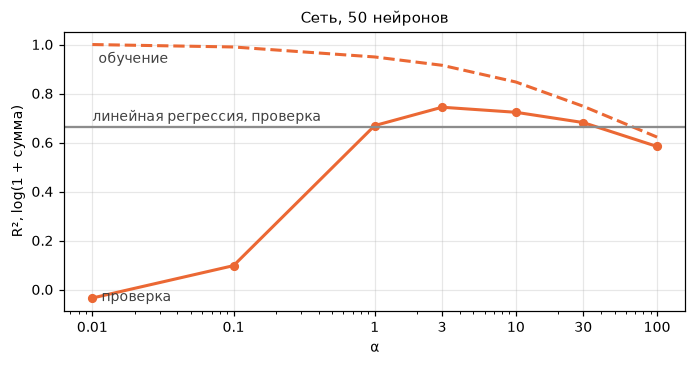

In [6]:
best = {name.split("__")[-1]: setting for name, setting in search.best_params_.items()}
linear_search = cross_val_score(
    build_pipeline(LinearRegression(), CATEGORICAL, NUMERIC),
    X_train,
    value_train,
    cv=search_folds,
    scoring=log_r2,
).mean()
curve = results[results["layers"] == layer_names[best["hidden_layer_sizes"]]].sort_values("alpha")
color = NETWORK_COLOR

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(curve["alpha"], curve["mean_train_r2"], color=color, linewidth=2, linestyle="--")
ax.plot(curve["alpha"], curve["mean_test_r2"], color=color, linewidth=2, marker="o", markersize=5)
ax.axhline(linear_search, color="0.55", linewidth=1.5)
ax.annotate(
    "обучение",
    (curve["alpha"].iloc[0], curve["mean_train_r2"].iloc[0]),
    xytext=(4, -12),
    textcoords="offset points",
    color="0.25",
)
ax.annotate(
    "проверка",
    (curve["alpha"].iloc[0], curve["mean_test_r2"].iloc[0]),
    xytext=(6, -2),
    textcoords="offset points",
    color="0.25",
)
ax.annotate(
    "линейная регрессия, проверка",
    (ALPHAS[0], linear_search),
    xytext=(0, 4),
    textcoords="offset points",
    color="0.25",
)
ax.set_xscale("log")
ax.set_xticks(ALPHAS, [f"{alpha:g}" for alpha in ALPHAS])
ax.set_xlabel("α")
ax.set_ylabel("R², log(1 + сумма)")
ax.set_title(f"Сеть, {layer_names[best['hidden_layer_sizes']]} нейронов")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Лучший $R^2$ на проверке — при $\alpha = 3$, и разрыв между обучением и проверкой там
умеренный. Ниже итог подбора.

In [7]:
network = search.best_estimator_
mlp = network.regressor_["regressor"]
unconverged = results[results["unconverged"] > 0]
fits = len(results) * SEARCH_FOLDS

make_table(
    {
        "нейроны в слоях": layer_names[best["hidden_layer_sizes"]],
        "α": best["alpha"],
        "R² сети на 5 частях": round(search.best_score_, 3),
        "его стандартное отклонение по частям": round(
            search.cv_results_["std_test_r2"][search.best_index_], 3
        ),
        "R² линейной регрессии на тех же частях": round(linear_search, 3),
        "весов в сети": sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_),
        "итераций обучения": f"{mlp.n_iter_} из {MAX_ITER}",
        "обучений без сходимости": f"{unconverged['unconverged'].sum()} из {fits}",
        "α у несошедшихся обучений": ", ".join(
            f"{alpha:g}" for alpha in unconverged["alpha"].unique()
        ),
    }
)

,значение
,
нейроны в слоях,50
α,3
R² сети на 5 частях,0.744
его стандартное отклонение по частям,0.086
R² линейной регрессии на тех же частях,0.663
весов в сети,501
итераций обучения,1224 из 5000
обучений без сходимости,4 из 175
α у несошедшихся обучений,0.01


Лучшая сеть — один слой из 50 нейронов с $\alpha = 3$, $R^2 = 0.744$ против 0.663 у линейной
регрессии. Но при $\alpha$ от 3 до 30 все пять архитектур дают от 0.66 до 0.74, а у лучшей сети
$R^2$ на разных частях отклоняется от среднего на 0.086. Разница между архитектурами меньше этого
разброса, так что число нейронов почти не влияет на результат, влияет $\alpha$.

Обучение лучшей сети сошлось за 1224 итерации из 5000. Не сошлись 4 обучения из 175, все с
$\alpha = 0.01$, т. е. у сетей, которые и так переобучаются.

## 4. Сравнение с линейной регрессией

Сеть с подобранными параметрами и линейная регрессия обучены на одних и тех же 117 сделках и
проверены на тех же 39. Кроме того, обе модели проверены кросс-валидацией на 10 частях, параметры
сети в ней берутся найденные выше. Они подбирались на 117 из 156 сделок, поэтому оценка сети на
кросс-валидации может быть немного завышена.

Метрики считаются в логарифмической шкале: в долларах их определяют несколько крупнейших продаж
Маска. Разность логарифмов равна логарифму отношения, поэтому MAE в логарифмах переводится в разы:
в среднем прогноз отличается от факта в $e^{\mathrm{MAE}}$ раз.

In [8]:
folds = KFold(FOLDS, shuffle=True, random_state=RANDOM_STATE)
linear = build_pipeline(LinearRegression(), CATEGORICAL, NUMERIC).fit(X_train, value_train)
fitted = {"линейная регрессия": linear, "сеть": network}
estimators = {
    "линейная регрессия": build_pipeline(LinearRegression(), CATEGORICAL, NUMERIC),
    "сеть": build_mlp(**best),
}
log_value = np.log1p(value)
holdout = {name: model.regressor_.predict(X_test) for name, model in fitted.items()}
predicted = {
    name: pd.Series(
        np.log1p(cross_val_predict(model, X_tesla, value, cv=folds)), index=tesla.index
    )
    for name, model in estimators.items()
}


def log_report(actual, prediction):
    report = regression_report(actual, prediction)
    return {**report, "во сколько раз": np.exp(report["MAE"])}


pd.DataFrame(
    {
        **{
            (f"отложенная выборка, {len(X_test)}", name): log_report(
                log_value[X_test.index], prediction
            )
            for name, prediction in holdout.items()
        },
        **{
            (f"кросс-валидация, {FOLDS} частей", name): log_report(log_value, prediction)
            for name, prediction in predicted.items()
        },
    }
).round(3)

отложенная выборка, 39        кросс-валидация, 10 частей       
                   линейная регрессия   сеть         линейная регрессия   сеть
R²                              0.668  0.626                      0.685  0.730
MAE                             2.401  1.934                      2.271  1.497
RMSE                            3.271  3.473                      3.259  3.022
во сколько раз                 11.031  6.917                      9.688  4.469

На кросс-валидации сеть лучше: $R^2 = 0.730$ против 0.685, и в среднем прогноз отличается от факта
в 4.5 раза против 9.7. На отложенной выборке $R^2$ сети ниже, 0.626 против 0.668, хотя MAE у неё
меньше: 1.93 против 2.40, т. е. в 6.9 раза против 11. Значит, на большинстве проверочных сделок
сеть точнее. При этом RMSE у неё больше, 3.47 против 3.27, т. е. среди её ошибок есть крупные. Ниже
две проверочные сделки с наибольшей ошибкой сети.

In [9]:
holdout_log = {name: pd.Series(prediction, X_test.index) for name, prediction in holdout.items()}
network_squared = (log_value[X_test.index] - holdout_log["сеть"]) ** 2
worst = network_squared.nlargest(2).index
train_options = tesla.loc[X_train.index].query("transaction == 'Option Exercise'")
insider = tesla.loc[worst, "insider"]

pd.DataFrame(
    {
        "инсайдер": insider,
        "дата": tesla.loc[worst, "date"].dt.strftime("%d.%m.%Y"),
        "сумма, $": value[worst],
        "факт, log": log_value[worst].round(2),
        "прогноз линейной регрессии, log": holdout_log["линейная регрессия"][worst].round(2),
        "прогноз сети, log": holdout_log["сеть"][worst].round(2),
        "доля в квадрате ошибки сети": (network_squared[worst] / network_squared.sum()).round(3),
        "его опционов в обучении": insider.map(train_options["insider"].value_counts()),
        "из них нулевых": insider.map(
            train_options.loc[train_options["value"] == 0, "insider"].value_counts()
        ),
    }
).T

,56,107
инсайдер,Taneja Vaibhav,Kirkhorn Zachary
дата,10.06.2022,31.12.2021
"сумма, $",138300,177024
"факт, log",11.84,12.08
"прогноз линейной регрессии, log",4.79,5.84
"прогноз сети, log",-1.11,1.18
доля в квадрате ошибки сети,0.357,0.253
его опционов в обучении,6,5
из них нулевых,4,4


Обе сделки — платные исполнения опционов главного бухгалтера и финансового директора на 138 и 177
тыс. \$. Сеть предсказала для них логарифм −1.11 и 1.18, т. е. сумму меньше 3 \$. В обучающей
выборке большинство исполнений опционов у этих инсайдеров — нулевые сделки, и сеть выучила
сочетание «опцион этого руководителя — сумма около нуля». Линейная регрессия такое сочетание
выучить не может, её прогноз — среднее между нулевыми и платными сделками, и ошибка меньше.

На двух этих сделках сеть ошиблась на 13.0 и 10.9 в логарифмах. Это 61% суммы квадратов её ошибок
на отложенной выборке, и именно они опустили $R^2$. В 39 проверочных сделок попало всего 10 платных
опционов, поэтому отложенная выборка так чувствительна к отдельным сделкам. Надёжнее
кросс-валидация: каждая из 156 сделок ровно один раз попадает в проверку.

## 5. Применимость нейронной сети

Ниже ошибки обеих моделей по группам сделок на кросс-валидации. «MAE» — средний модуль остатка в
логарифмах, «доля квадрата ошибки» — доля группы в сумме квадратов остатков модели.

In [10]:
residuals = pd.DataFrame({name: log_value - prediction for name, prediction in predicted.items()})
squared = residuals**2
pd.concat(
    {
        "MAE": residuals.abs().groupby(group).mean(),
        "доля квадрата ошибки": squared.groupby(group).sum() / squared.sum(),
    },
    axis=1,
).loc[list(GROUPS)].round(3)

MAE        доля квадрата ошибки       
                           линейная регрессия   сеть   линейная регрессия   сеть
продажа                                 1.002  0.432                0.112  0.031
платное исполнение опциона              3.267  2.529                0.333  0.541
нулевая сделка                          7.092  5.122                0.555  0.428

Сеть точнее во всех трёх группах. Сильнее всего ошибка упала на продажах, с 1.00 до 0.43, т. е. с
2.7 до 1.5 раза. На нулевых сделках она уменьшилась с 7.09 до 5.12, но эти 18 сделок по-прежнему
дают 43% суммы квадратов ошибок сети, а платные опционы — ещё 54%. Ниже прогнозы обеих моделей на
кросс-валидации.

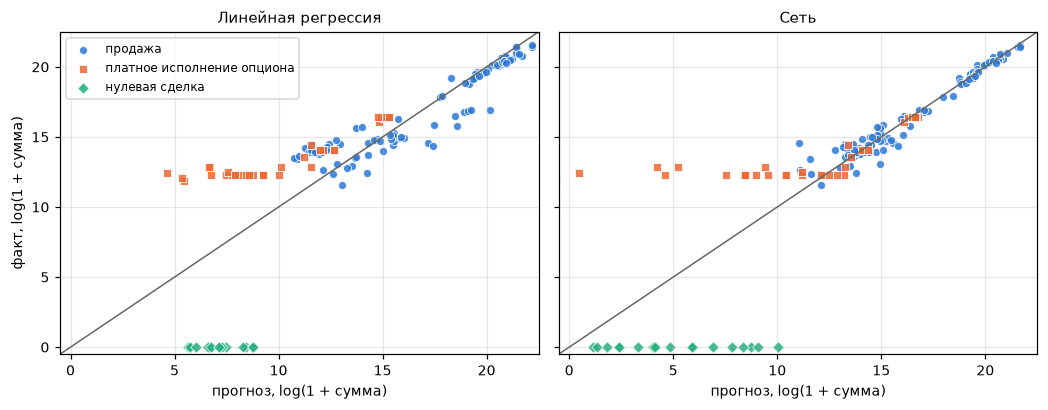

In [11]:
def draw_groups(ax, x, y):
    for name, (color, marker) in GROUPS.items():
        members = group == name
        ax.scatter(
            x[members],
            y[members],
            color=color,
            marker=marker,
            s=28,
            alpha=0.85,
            edgecolors="white",
            linewidths=0.6,
            label=name,
        )


limits = (-0.5, 22.5)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8), sharey=True)
for ax, (name, prediction) in zip(axes, predicted.items(), strict=True):
    draw_groups(ax, prediction, log_value)
    ax.plot(limits, limits, color="0.4", linewidth=1)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_xlabel("прогноз, log(1 + сумма)")
    ax.set_title(name.capitalize())
    ax.grid(alpha=0.3)
axes[0].set_ylabel("факт, log(1 + сумма)")
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

У сети продажи легли ближе к диагонали, а прогнозы нулевых сделок сдвинулись вниз. Но сдвинулись
они вместе с частью платных опционов: сеть не может отличить нулевую сделку от платной. Признаков,
которые бы их различали, в задаче нет, у тех же руководителей в те же месяцы есть сделки обоих
видов. Нелинейность тут не помогает: сеть выбирает между нулём и платной суммой по сочетанию
инсайдера и месяца, и если выбрала неверно, ошибается сильнее линейной регрессии. Это и случилось
на отложенной выборке.

Чтобы отделить эффект нелинейности от нулевых сделок, обе модели обучены заново без них. Параметры
сети те же. Ниже кросс-валидация на 138 ненулевых сделках и MAE по группам.

In [12]:
nonzero = {
    name: pd.Series(
        np.log1p(cross_val_predict(model, X_tesla[~zero], value[~zero], cv=folds)),
        index=X_tesla.index[~zero],
    )
    for name, model in estimators.items()
}
nonzero_residuals = pd.DataFrame(
    {name: log_value[~zero] - prediction for name, prediction in nonzero.items()}
)
pd.concat(
    [
        pd.DataFrame(
            {
                name: log_report(log_value[~zero], prediction)
                for name, prediction in nonzero.items()
            }
        ),
        nonzero_residuals.abs().groupby(group).mean().rename(index=lambda name: f"MAE, {name}"),
    ]
).round(3)

,линейная регрессия,сеть
R²,0.951,0.978
MAE,0.515,0.298
RMSE,0.662,0.439
во сколько раз,1.673,1.348
"MAE, платное исполнение опциона",0.729,0.256
"MAE, продажа",0.430,0.315


Без нулевых сделок линейная регрессия даёт $R^2 = 0.951$, сеть — 0.978, а средняя ошибка
уменьшилась с 1.67 до 1.35 раза. На платных опционах MAE упала почти втрое, с 0.73 до 0.26, на
продажах — с 0.43 до 0.32.

Скорее всего, сеть выигрывает на сочетаниях признаков, как нейрон из примера в разделе 2. Цена
исполнения опционов у каждого инсайдера своя, а линейная регрессия даёт продаже один вес для всех
должностей. Цена акции за период падала неравномерно, а время линейная регрессия описывает одним
весом месяца и одним весом года.

### Оценка метода

На всём наборе многослойный персептрон подходит для задачи немного лучше линейной регрессии. На
кросс-валидации $R^2$ вырос с 0.685 до 0.730, но на отложенной выборке сеть проиграла из-за двух
сделок. Нулевые сделки сеть не отделила: в признаках нет информации, которая бы их отличала, и
нелинейность этого не заменяет. Вместо этого сеть иногда уверенно предсказывает ноль для платной
сделки.

Для платных сделок сеть подходит лучше линейной регрессии: $R^2 = 0.978$ против 0.951, прогноз в
среднем отличается от факта в 1.35 раза. Скорее всего, нелинейность позволяет учесть, что цена
исполнения опционов у каждого инсайдера своя, а цена акции менялась во времени не по прямой.

Цена этого — 501 вес на 117 обучающих сделок. Без регуляризации сеть запоминает обучающую выборку,
и подбор $\alpha$ здесь обязателен.

## Выводы

1. Сформулирована задача регрессии: предсказать логарифм суммы сделки инсайдера Tesla по типу
   сделки, должности, числу акций, месяцу и году. Сеть `MLPRegressor` и линейная регрессия стоят в
   одном конвейере с one-hot кодированием и стандартизацией и сравниваются на одном разбиении.
2. Число нейронов и $\alpha$ подобраны `GridSearchCV` на 117 обучающих сделках. Лучшая сеть — один
   слой из 50 нейронов с $\alpha = 3$. Архитектура почти не влияет на качество, $\alpha$ влияет
   сильно: при $\alpha \le 0.1$ сети запоминают обучающую выборку, $R^2$ на обучении доходит до
   1.00, а на проверке опускается почти до нуля.
3. На кросс-валидации сеть лучше линейной регрессии: $R^2 = 0.730$ против 0.685, прогноз отличается
   от факта в 4.5 раза против 9.7. На отложенной выборке $R^2$ сети ниже, 0.626 против 0.668, из-за
   двух платных опционов, для которых сеть предсказала почти ноль.
4. Нулевые сделки сеть не отделила, они дают 43% суммы квадратов её ошибок. Без них сеть точнее
   линейной регрессии, $R^2 = 0.978$ против 0.951.
5. На 156 сделках выигрыш от сети небольшой и неустойчивый, а интерпретировать её веса нельзя. Для
   этой задачи сеть подходит, если отделить нулевые сделки и собрать больше данных.

## Контрольные вопросы

**1. Какую задачу для решения вы сформулировали?**

Задача регрессии: по типу сделки, должности инсайдера, числу акций, месяцу и году предсказать сумму
сделки инсайдера Tesla. Это обучение с учителем: сумма каждой сделки в наборе известна, и модель
учится восстанавливать её по признакам. Модель предсказывает логарифм суммы, т. к. суммы
различаются на несколько порядков. Цена акции в признаки не входит: вместе с числом акций она даёт
сумму без всякой модели.

**2. Как вы оценили качество решения?**

Метриками $R^2$, MAE и RMSE на отложенной выборке из 39 сделок и кросс-валидацией на 10 частях, в
логарифмической шкале: в долларах метрики определяются несколькими продажами Маска. Сеть
сравнивалась с линейной регрессией на тех же разбиениях. Параметры сети подбирались
кросс-валидацией только на обучающей выборке, и переобучение проверено сравнением $R^2$ на
обучающих и проверочных частях.

Кроме того, ошибки разобраны по группам сделок. Группу нулевых сделок сеть описать не может, и это
подтверждено обучением обеих моделей без них.

**3. Расскажите подробнее об используемой вами модели.**

Многослойный персептрон — сеть прямого распространения: признаки проходят через скрытые слои
нейронов, каждый нейрон считает взвешенную сумму входов и применяет функцию активации, в нашем
случае ReLU. Без функции активации сеть сводится к линейной модели, с ней — описывает нелинейные
зависимости и сочетания признаков. Веса подбираются градиентным методом, градиент считается
обратным распространением ошибки. Аналитического решения нет: обучение сходится к локальному
минимуму, который зависит от начальных весов, и может не сойтись за отведённое число итераций.
Число слоёв и нейронов подбирается экспериментально. Сети нужна стандартизация признаков и
регуляризация $\alpha$, а на малой выборке она легко переобучается. Веса сети не интерпретируются
по отдельности.